In [1]:
# imports
import sys
from pathlib import Path

import numpy as np
from scipy.stats import gaussian_kde
import joblib

# Garante que a raiz do projeto esteja disponível para importação
raiz_projeto = Path.cwd().parent
if str(raiz_projeto) not in sys.path:
    sys.path.insert(0, str(raiz_projeto))

import math
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

import catalogo_variaveis
import unidades
import config

# Carga dos dados

In [3]:
df = pd.read_csv("../data/processed/dataset_soja.csv")

In [4]:
df.shape

(8934, 67)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8934 entries, 0 to 8933
Data columns (total 67 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   localidade              8934 non-null   str    
 1   ano                     8934 non-null   int64  
 2   producao                8934 non-null   float64
 3   rendimento              8934 non-null   float64
 4   area_colhida            8934 non-null   float64
 5   area_plantada           8934 non-null   float64
 6   produto                 8934 non-null   str    
 7   cod_ibge                8934 non-null   int64  
 8   razao_colhida_plantada  8934 non-null   float64
 9   perda_flag              8934 non-null   int64  
 10  rendimento_calc         8934 non-null   float64
 11  rend_repetido           8934 non-null   int64  
 12  y_log                   8934 non-null   float64
 13  peso                    8934 non-null   float64
 14  implant_prec            8934 non-null   float64
 15

In [6]:
df.describe()

,ano,producao,rendimento,area_colhida,area_plantada,cod_ibge,razao_colhida_plantada,perda_flag,rendimento_calc,rend_repetido,...,argila,silte,prof_max_cm,n_perfis,lat,lon,solo_imputado,solo_dist_km,cad_mm,lag1_rel
count,8934.000000,8934.000000,8934.000000,8934.000000,8934.000000,8.934000e+03,8934.000000,8934.000000,8934.000000,8934.000000,...,7982.000000,7982.000000,7982.000000,1495.000000,8934.000000,8934.000000,8934.000000,8934.000000,8934.000000,7961.000000
mean,2014.072644,7169.701589,2790.053280,2364.676964,2371.532796,3.528799e+06,0.998335,0.003358,2790.079215,0.451198,...,326.208991,82.520337,106.687108,11.931773,-21.813639,-49.105067,0.832662,43.997624,84.057934,-0.009560
std,7.566059,19141.760281,661.586181,5688.968984,5704.916056,1.654537e+04,0.029653,0.057854,661.574681,0.497640,...,156.003265,51.923071,42.486322,39.129766,1.068733,1.393255,0.373298,28.150562,19.953006,0.213604
min,2000.000000,15.000000,800.000000,10.000000,10.000000,3.500105e+06,0.150000,0.000000,800.000000,0.000000,...,18.000000,2.000000,20.000000,2.000000,-24.772000,-52.836900,0.000000,0.000000,18.090000,-1.203973
25%,2007.000000,463.250000,2400.000000,200.000000,200.000000,3.514957e+06,1.000000,0.000000,2400.000000,0.000000,...,215.500000,45.166667,75.833333,4.000000,-22.651600,-50.200200,1.000000,24.702710,75.020000,-0.117783
50%,2015.000000,1484.500000,2719.500000,540.000000,544.000000,3.529203e+06,1.000000,0.000000,2719.641816,0.000000,...,317.333333,73.500000,101.666667,6.000000,-21.735850,-49.142500,1.000000,46.058412,82.358222,0.000000
75%,2021.000000,5400.000000,3194.500000,1955.000000,1967.500000,3.543204e+06,1.000000,0.000000,3194.871795,1.000000,...,438.333333,114.000000,137.500000,8.000000,-20.940500,-47.938500,1.000000,63.215307,96.366667,0.130736
max,2025.000000,360000.000000,5400.000000,82000.000000,82000.000000,3.557303e+06,1.000000,1.000000,5400.000000,1.000000,...,762.500000,321.000000,450.000000,310.000000,-19.907300,-45.060000,1.000000,116.777435,137.200000,0.765654


In [7]:
df.describe(include="object")

C:\Users\Samsung\AppData\Local\Temp\ipykernel_40224\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,localidade,produto
count,8934,8934
unique,521,1
top,Aguaí - SP,soja
freq,26,8934


In [8]:
df.loc[df["ano"] >= 2022]

,localidade,ano,producao,rendimento,area_colhida,area_plantada,produto,cod_ibge,razao_colhida_plantada,perda_flag,...,argila,silte,prof_max_cm,n_perfis,lat,lon,solo_imputado,solo_dist_km,cad_mm,lag1_rel
7036,Adamantina - SP,2022,1034.0,2068.0,500.0,500.0,soja,3500105,1.0,0,...,117.333333,14.166667,65.000000,NaN,-21.5767,-51.0568,1,46.306230,46.206333,0.000000
7037,Adolfo - SP,2022,3673.0,3601.0,1020.0,1020.0,soja,3500204,1.0,0,...,215.500000,19.166667,143.333333,NaN,-21.2887,-49.6533,1,63.215307,79.540000,-0.356675
7038,Aguaí - SP,2022,11127.0,3709.0,3000.0,3000.0,soja,3500303,1.0,0,...,449.000000,113.666667,88.000000,NaN,-22.0500,-47.0403,1,29.899939,96.412800,0.180653
7039,Agudos - SP,2022,2363.0,3501.0,675.0,675.0,soja,3500709,1.0,0,...,271.666667,72.666667,107.000000,NaN,-22.5719,-49.1088,1,47.005544,90.453333,0.200762
7040,Alambari - SP,2022,7260.0,3300.0,2200.0,2200.0,soja,3500758,1.0,0,...,160.000000,40.000000,87.500000,2.0,-23.5489,-47.8691,0,0.000000,67.900000,0.139762
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8929,Águas de Santa Bárbara - SP,2025,35778.0,4061.0,8810.0,8810.0,soja,3500550,1.0,0,...,292.666667,67.500000,102.500000,NaN,-22.8580,-49.2610,1,58.814446,91.513333,0.060014
8930,Álvares Florence - SP,2025,6480.0,3600.0,1800.0,1800.0,soja,3501202,1.0,0,...,438.333333,143.666667,73.333333,NaN,-20.2896,-49.9203,1,56.954996,82.358222,-0.169076
8931,Álvares Machado - SP,2025,112.0,2240.0,50.0,50.0,soja,3501301,1.0,0,...,NaN,NaN,NaN,NaN,-22.1315,-51.5149,1,81.863877,80.000000,-0.146097
8932,Álvaro de Carvalho - SP,2025,200.0,2000.0,100.0,100.0,soja,3501400,1.0,0,...,106.666667,62.833333,82.333333,NaN,-22.0865,-49.7340,1,21.086588,62.633711,-0.300105


In [11]:
df = df[df["solo_imputado"].eq(0)]

# Análise das variáveis numéricas

## Qualidade dos dados

In [13]:
def plot_missing_values(df, figsize=(12, 6)):
    missing_pct = df.isnull().mean().mul(100).sort_values(ascending=False)

    missing_pct = missing_pct[missing_pct > 0]

    if missing_pct.empty:
        print("Nenhuma feature possui valores ausentes.")
        return

    plt.figure(figsize=figsize)

    ax = sns.barplot(x=missing_pct.values, y=missing_pct.index, color="steelblue")

    ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)

    plt.title("Porcentagem de Valores Ausentes por Feature")
    plt.xlabel("Valores ausentes (%)")
    plt.ylabel("Features")
    plt.xlim(0, min(100, missing_pct.max() * 1.15))
    plt.tight_layout()
    plt.show()

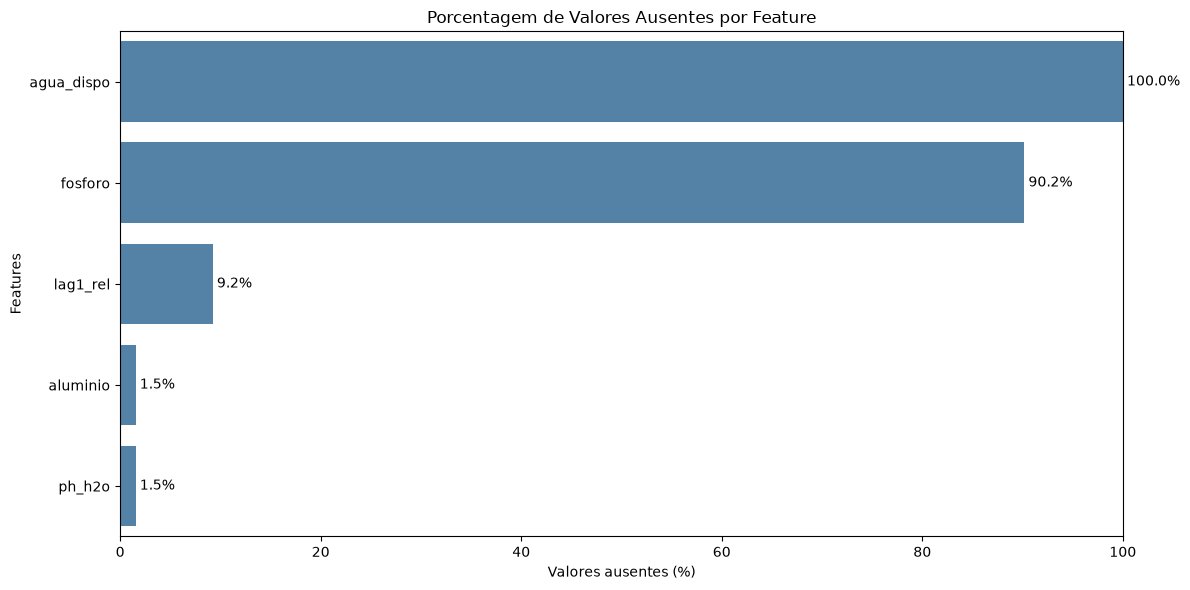

In [14]:
plot_missing_values(df)

In [15]:
# Dropando colunas com mais de 30% de valores ausentes
df.drop(columns=df.columns[df.isnull().mean() > 0.30], inplace=True)

In [16]:
def analyze_missing_rows(df, threshold=0.30):
    missing_count = df.isnull().sum(axis=1)
    missing_pct = df.isnull().mean(axis=1) * 100

    result = pd.DataFrame(
        {
            "linha": df.index,
            "features_ausentes": missing_count.values,
            "features_ausentes_pct": missing_pct.values,
        }
    )

    result = (
        result[result["features_ausentes_pct"] > threshold * 100]
        .sort_values("features_ausentes_pct", ascending=False)
        .reset_index(drop=True)
    )

    print(f"Total de linhas: {len(df)}")
    print(f"Linhas com mais de {threshold:.0%} de features ausentes: {len(result)}")
    print(f"Percentual das linhas: {len(result) / len(df) * 100:.2f}%")

    return result

In [17]:
df_missing_rows = analyze_missing_rows(df, threshold=0.10)

display(df_missing_rows)

Total de linhas: 1495
Linhas com mais de 10% de features ausentes: 0
Percentual das linhas: 0.00%


,linha,features_ausentes,features_ausentes_pct


In [18]:
# Dropping enchimento_dias_geada_d
df.drop(columns=["enchimento_dias_geada"], inplace=True)

## Univariada

In [19]:
columns_to_plot = [
    "ano",
    "producao_t",
    "rendimento_kg_ha",
    "area_colhida_ha",
    "area_plantada_ha",
    "peso",
]

columns_to_plot_implant = [
    "implant_prec",
    "implant_tmax",
    "implant_tmin",
    "implant_rad",
    "implant_defic",
    "implant_estresse",
    "implant_dias_calor",
    "implant_dias_geada",
    "implant_seca_max",
    "implant_gd",
    "implant_umsolo",
]

In [20]:
def plot_histograms_kde(df, columns, bins=30, ncols=2):
    nrows = math.ceil(len(columns) / ncols)

    fig, axes = plt.subplots(
        nrows, ncols, figsize=(6 * ncols, 5 * nrows), squeeze=False
    )
    axes = axes.flatten()

    for ax, col in zip(axes, columns):
        data = df[col].dropna()

        if data.empty:
            ax.set_title(f"Sem dados: {col}")
            continue

        q1 = data.quantile(0.25)
        q3 = data.quantile(0.75)
        iqr = q3 - q1
        limite_superior = q3 + 3.5 * iqr

        x_min = data.min()
        data_filtrada = data[data <= limite_superior]
        bins_range = np.linspace(x_min, limite_superior, bins + 1)

        ax.hist(
            data_filtrada,
            bins=bins_range,
            density=True,
            color="skyblue",
            edgecolor="black",
            alpha=0.6,
            label="Histograma",
        )

        if len(data_filtrada) > 1 and data_filtrada.nunique() > 1:
            kde = gaussian_kde(data_filtrada)
            x = np.linspace(x_min, limite_superior, 300)
            ax.plot(x, kde(x), color="red", linewidth=2, label="KDE")

        media = data_filtrada.mean()
        mediana = data_filtrada.median()

        ax.axvline(
            media,
            color="blue",
            linestyle="--",
            linewidth=2,
            label=f"Média: {media:.2f}",
        )
        ax.axvline(
            mediana,
            color="green",
            linestyle="-.",
            linewidth=2,
            label=f"Mediana: {mediana:.2f}",
        )

        ax.set_xlim(x_min, limite_superior)
        ax.set_title(f"Distribuição de {col}")
        ax.set_xlabel(col)
        ax.set_ylabel("Densidade")
        ax.legend()

    for ax in axes[len(columns) :]:
        fig.delaxes(ax)

    plt.tight_layout()
    plt.show()

In [21]:
original_columns = df.columns.tolist()
df = unidades.para_exportacao(df)

In [22]:
df.describe()

,ano,producao_t,rendimento_kg_ha,area_colhida_ha,area_plantada_ha,cod_ibge,razao_colhida_plantada,perda_flag,rendimento_calc_kg_ha,rend_repetido,...,argila_g_kg,silte_g_kg,prof_max_cm,n_perfis,lat,lon,solo_imputado,solo_dist_km,cad_mm,lag1_rel
count,1495.000000,1495.000000,1495.000000,1495.000000,1495.000000,1.495000e+03,1495.000000,1495.000000,1495.000000,1495.000000,...,1495.000000,1495.000000,1495.000000,1495.000000,1495.000000,1495.000000,1495.0,1495.0,1495.000000,1357.000000
mean,2014.097659,9701.236789,2810.618729,3149.126421,3167.658194,3.528276e+06,0.998697,0.002676,2810.642366,0.537793,...,359.189632,89.209365,106.560201,11.931773,-22.018673,-48.206455,0.0,0.0,81.014837,0.000543
std,7.533670,30839.310601,622.861674,8740.480201,8782.405305,1.657277e+04,0.025718,0.051674,622.850093,0.498736,...,211.718693,70.631884,67.817618,39.129766,1.094830,1.326846,0.0,0.0,25.098154,0.200320
min,2000.000000,15.000000,942.000000,10.000000,10.000000,3.500402e+06,0.270270,0.000000,941.674401,0.000000,...,18.000000,2.000000,20.000000,2.000000,-24.421500,-52.836900,0.0,0.0,18.090000,-1.053002
25%,2007.000000,594.500000,2400.000000,214.000000,214.000000,3.513207e+06,1.000000,0.000000,2400.000000,0.000000,...,160.000000,34.500000,70.000000,4.000000,-22.880000,-48.861100,0.0,0.0,62.820000,-0.108000
50%,2015.000000,2000.000000,2717.000000,700.000000,700.000000,3.527504e+06,1.000000,0.000000,2716.981132,1.000000,...,331.500000,70.000000,85.000000,6.000000,-22.231000,-47.854600,0.0,0.0,79.860000,0.000000
75%,2021.000000,6000.000000,3160.500000,2000.000000,2000.000000,3.543402e+06,1.000000,0.000000,3160.560831,1.000000,...,555.000000,133.000000,130.000000,8.000000,-20.992100,-47.400900,0.0,0.0,98.600000,0.127833
max,2025.000000,360000.000000,5000.000000,82000.000000,82000.000000,3.556404e+06,1.000000,1.000000,5000.000000,1.000000,...,762.500000,321.000000,450.000000,310.000000,-19.922500,-45.060000,0.0,0.0,137.200000,0.575364


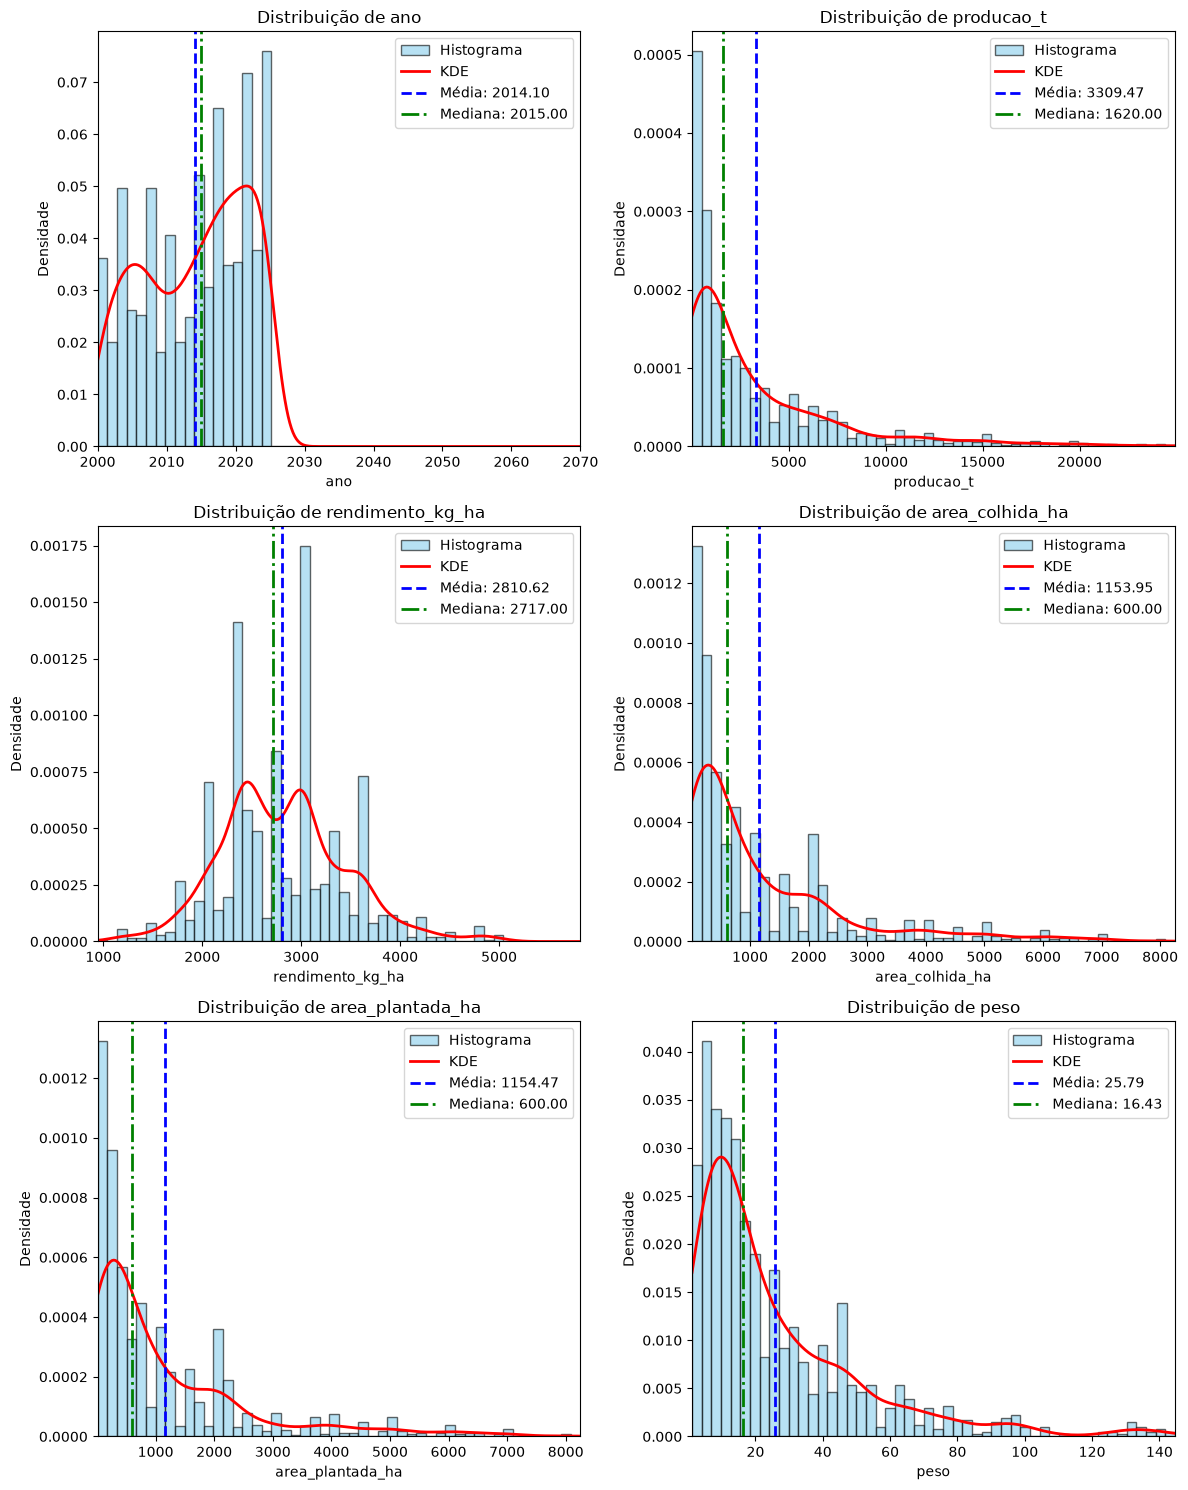

In [23]:
plot_histograms_kde(df, columns_to_plot, bins=50, ncols=2)

c:\Users\Samsung\Documents\Projetos\agro_ml\agro_ml\.venv\Lib\site-packages\numpy\lib\_histograms_impl.py:897: RuntimeWarning: divide by zero encountered in divide
  return n / db / n.sum(), bin_edges
c:\Users\Samsung\Documents\Projetos\agro_ml\agro_ml\.venv\Lib\site-packages\numpy\lib\_histograms_impl.py:897: RuntimeWarning: invalid value encountered in divide
  return n / db / n.sum(), bin_edges
c:\Users\Samsung\Documents\Projetos\agro_ml\agro_ml\.venv\Lib\site-packages\matplotlib\transforms.py:2496: RuntimeWarning: invalid value encountered in dot
  return Affine2D(np.dot(self._b.get_affine().get_matrix(),
C:\Users\Samsung\AppData\Local\Temp\ipykernel_40224\2603152844.py:58: UserWarning: Attempting to set identical low and high xlims makes transformation singular; automatically expanding.
  ax.set_xlim(x_min, limite_superior)
c:\Users\Samsung\Documents\Projetos\agro_ml\agro_ml\.venv\Lib\site-packages\numpy\lib\_histograms_impl.py:897: RuntimeWarning: divide by zero encountered in di

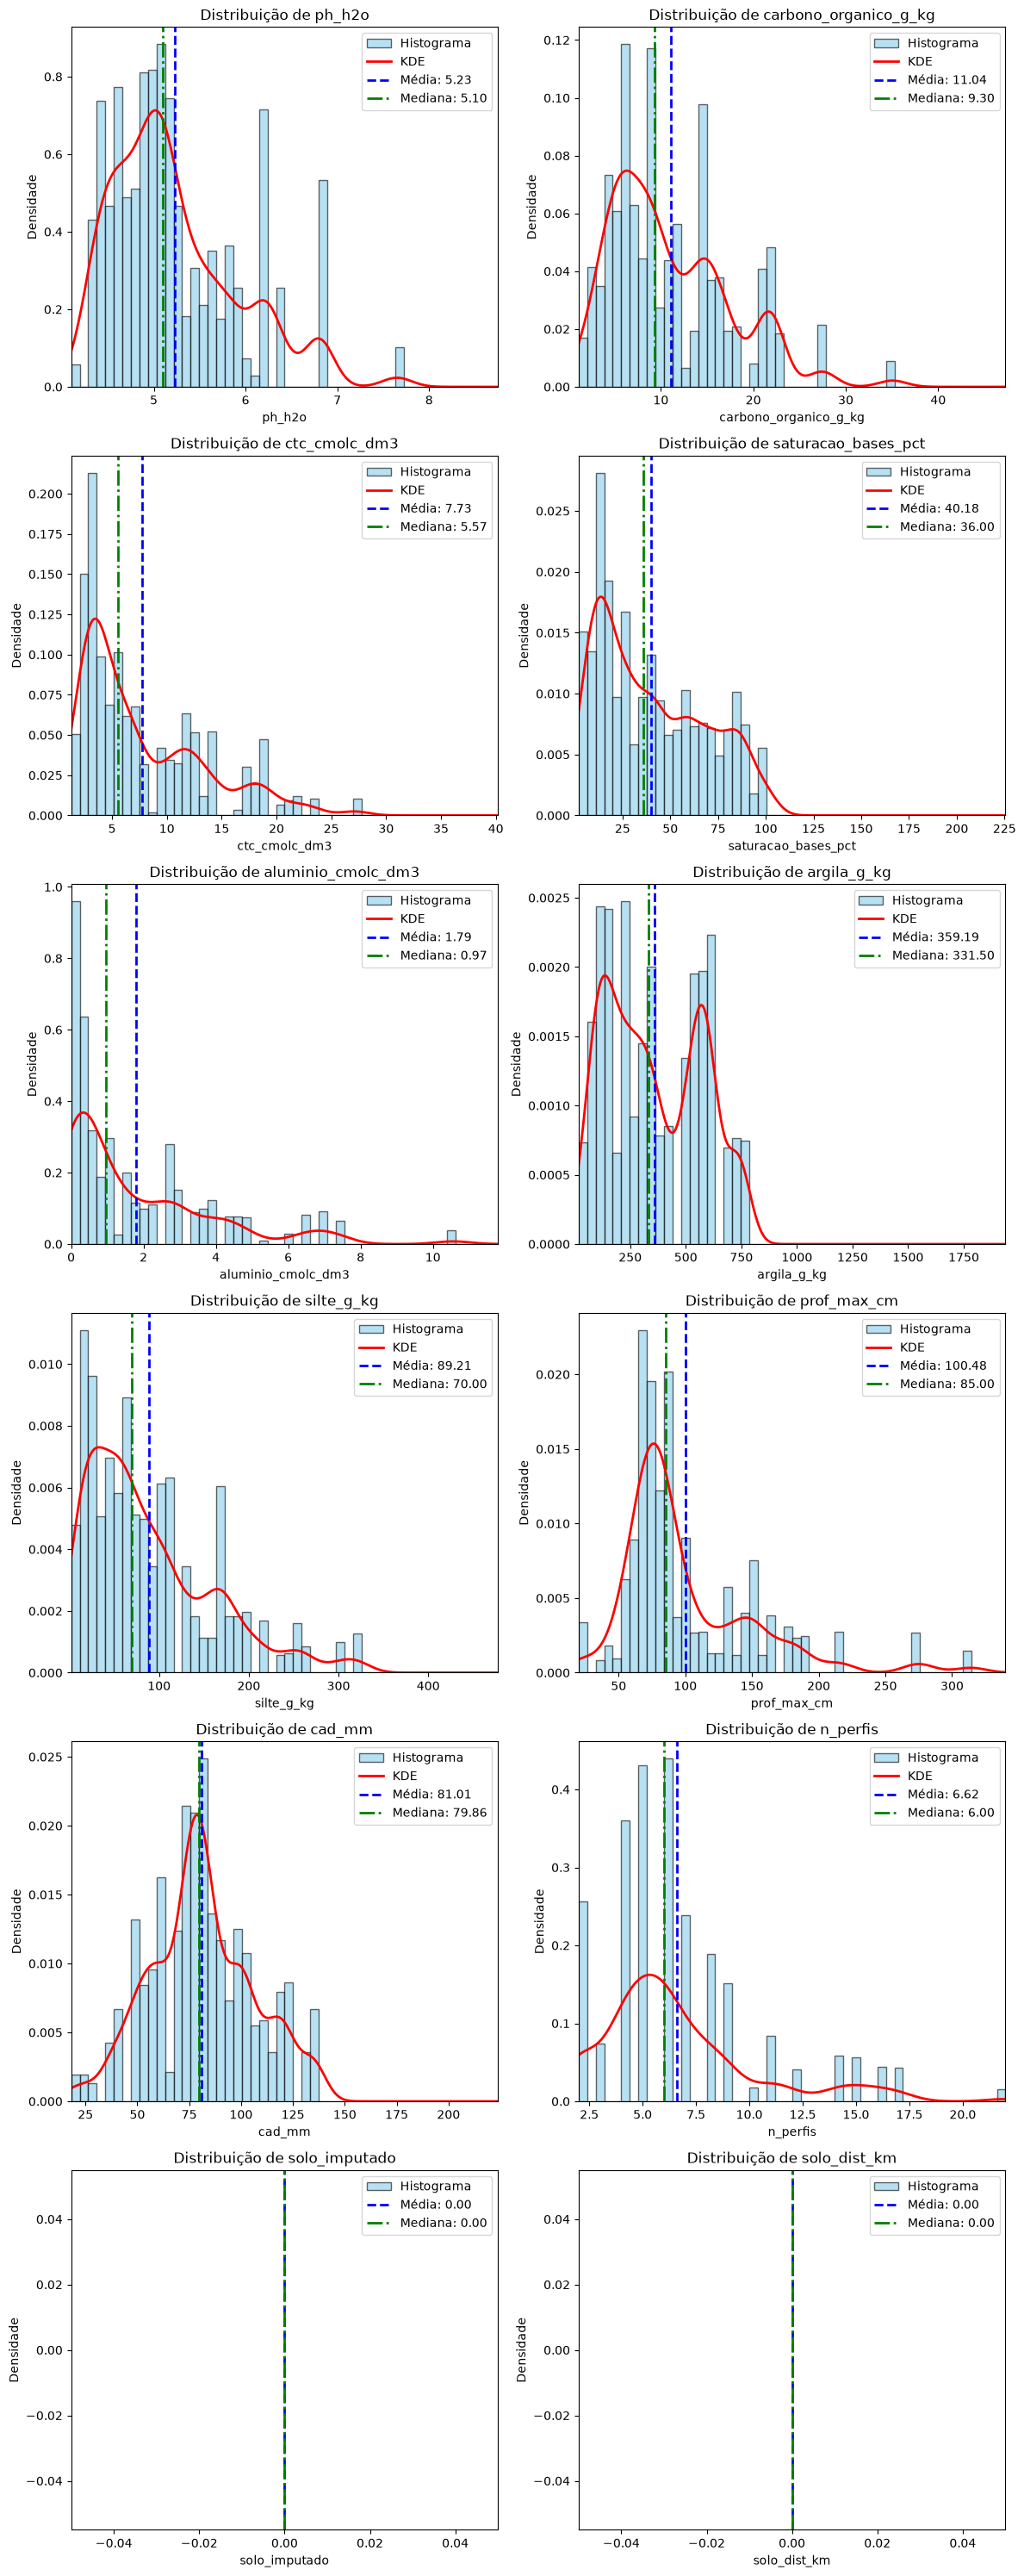

In [42]:
plot_histograms_kde(
    df, [x for x in catalogo_variaveis.SOLO if x in df.columns], bins=50, ncols=2
)

In [43]:
columns_to_plot_clim = [
    f"enchimento_{i}"
    for i in catalogo_variaveis.CLIMA_INDICADORES
    if f"enchimento_{i}" in df.columns
]

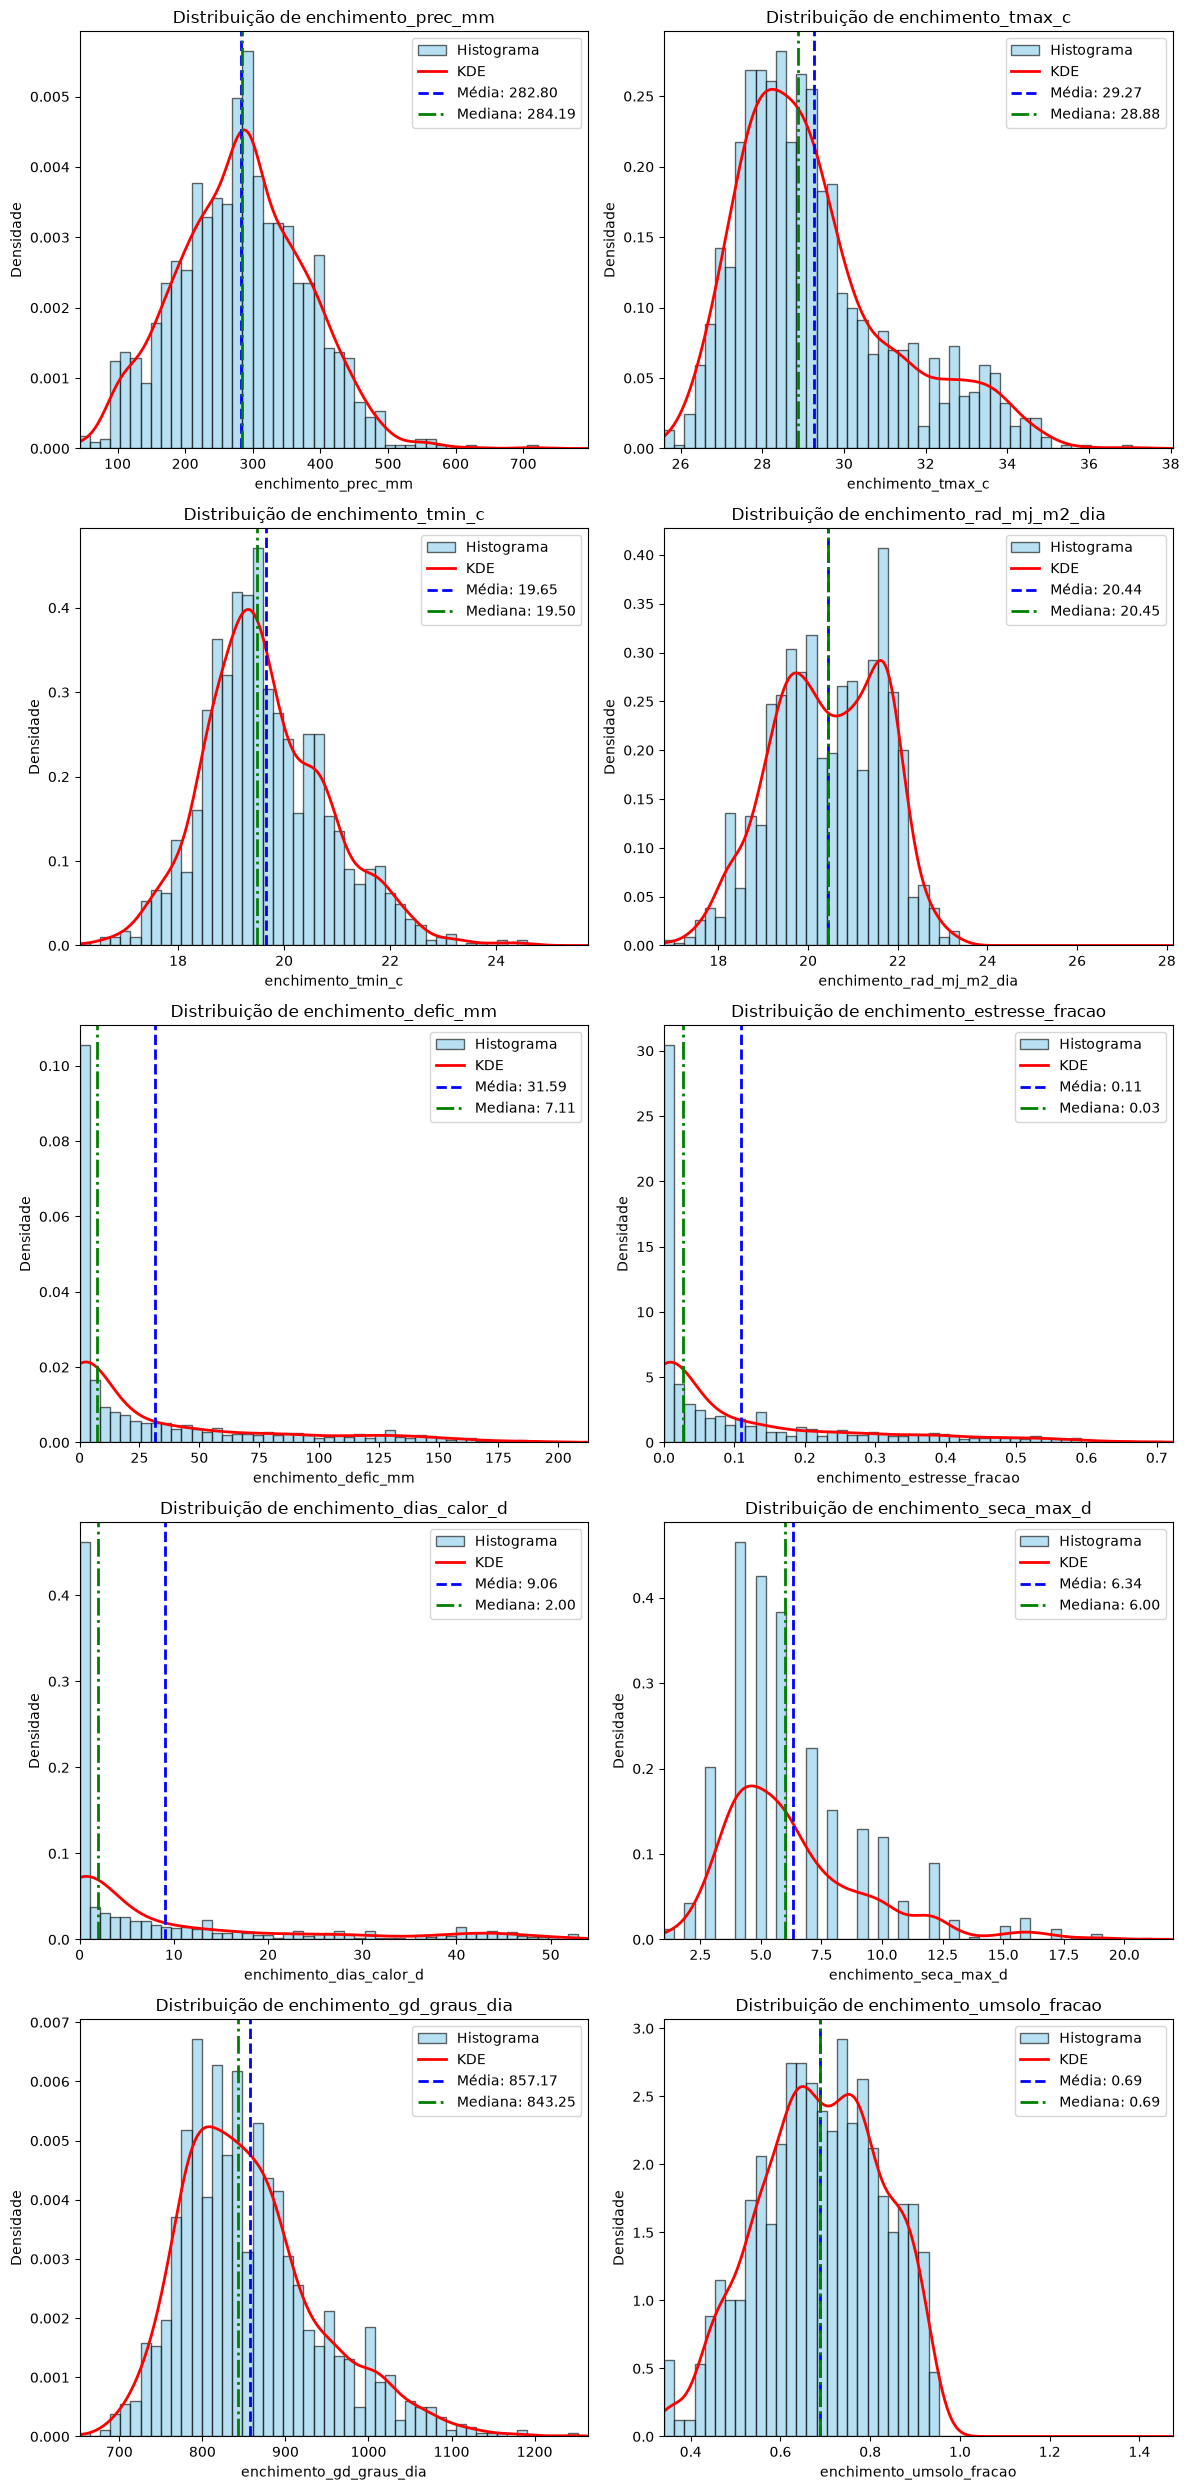

In [44]:
plot_histograms_kde(df, columns_to_plot_clim, bins=50, ncols=2)

In [97]:
def plot_boxplots(df, columns, ncols=2, showfliers=True):
    nrows = math.ceil(len(columns) / ncols)

    fig, axes = plt.subplots(
        nrows, ncols, figsize=(6 * ncols, 5 * nrows), squeeze=False
    )
    axes = axes.flatten()

    for ax, col in zip(axes, columns):
        data = df[col].dropna()

        if data.empty:
            ax.set_title(f"Sem dados: {col}")
            continue

        ax.boxplot(
            data,
            vert=True,
            patch_artist=True,
            showfliers=showfliers,
            boxprops=dict(facecolor="skyblue", edgecolor="black"),
            medianprops=dict(color="red", linewidth=2),
            whiskerprops=dict(color="black"),
            capprops=dict(color="black"),
            flierprops=dict(
                marker="o",
                markerfacecolor="orange",
                markeredgecolor="black",
                markersize=4,
                alpha=0.6,
            ),
        )

        ax.set_title(f"Boxplot de {col}")
        ax.set_ylabel(col)
        ax.set_xticks([])

    for ax in axes[len(columns) :]:
        fig.delaxes(ax)

    plt.tight_layout()
    plt.show()

C:\Users\Samsung\AppData\Local\Temp\ipykernel_26764\1819569262.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
C:\Users\Samsung\AppData\Local\Temp\ipykernel_26764\1819569262.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
C:\Users\Samsung\AppData\Local\Temp\ipykernel_26764\1819569262.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
C:\Users\Samsung\AppData\Local\Temp\ipykernel_26764\1819569262.py:16: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(
C:\Users\Samsung\AppData\Local\Temp\

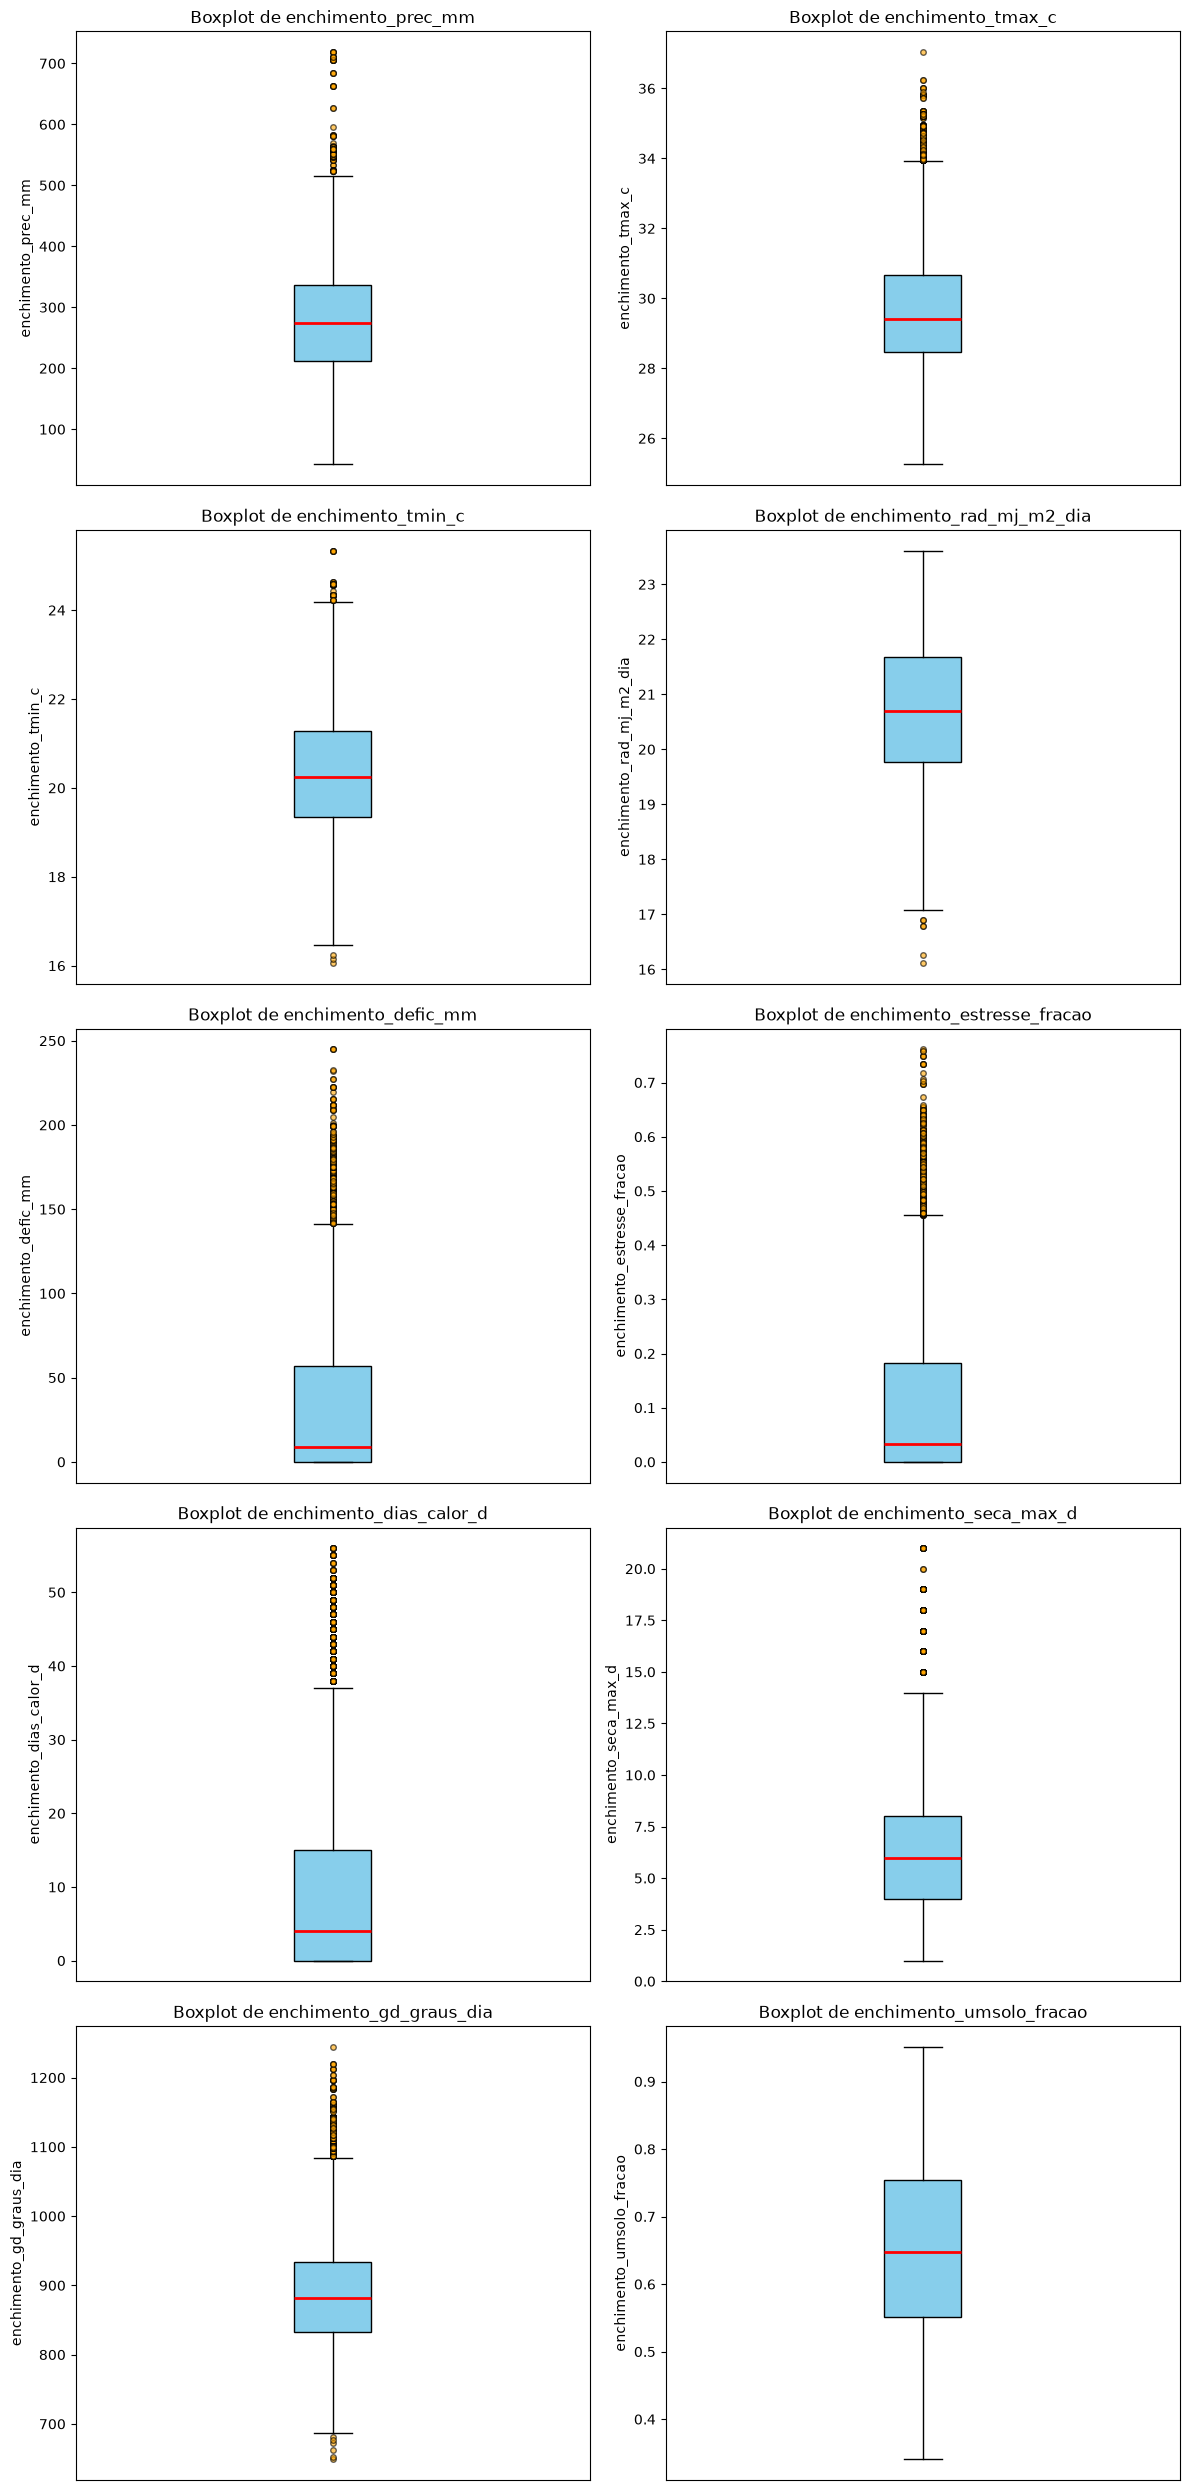

In [98]:
plot_boxplots(df, columns_to_plot_clim, ncols=2)

In [99]:
# Dropando colunas com menos de 80% de preenchimento
df_eda = df.copy()
df_eda.dropna(axis=1, thresh=int(0.8 * len(df_eda)), inplace=True)

# Análise multivariada

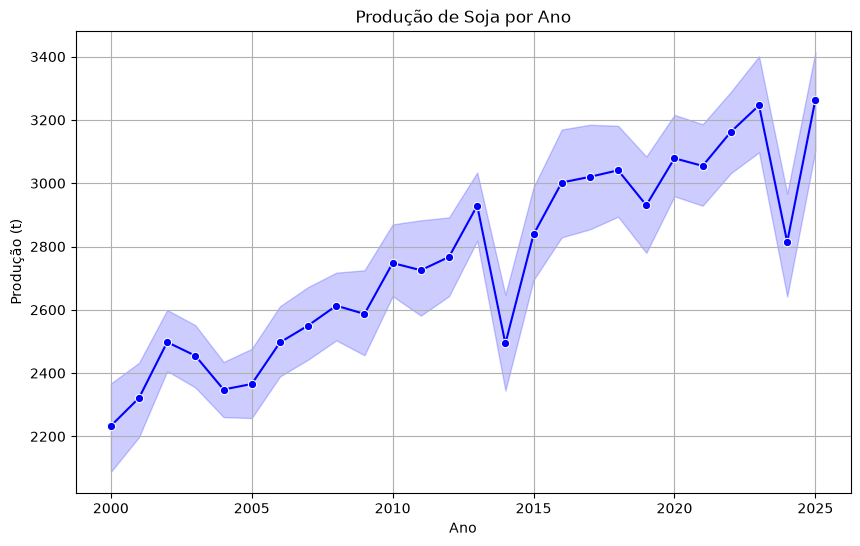

In [49]:
# Verificar produção por ano

plt.figure(figsize=(10, 6))

sns.lineplot(data=df, x="ano", y="rendimento_kg_ha", marker="o", color="blue")

plt.title("Produção de Soja por Ano")
plt.xlabel("Ano")
plt.ylabel("Produção (t)")
plt.grid()

Há uma clara tendencia de crescimento do rendimento ao longo do tempo. Essa é uma tendencia natural devido ao desenvolvimento tecnologico e aquecimento do clima

# Todo: Verificar as métricas entre o vale de 2014 e o pico de 2024

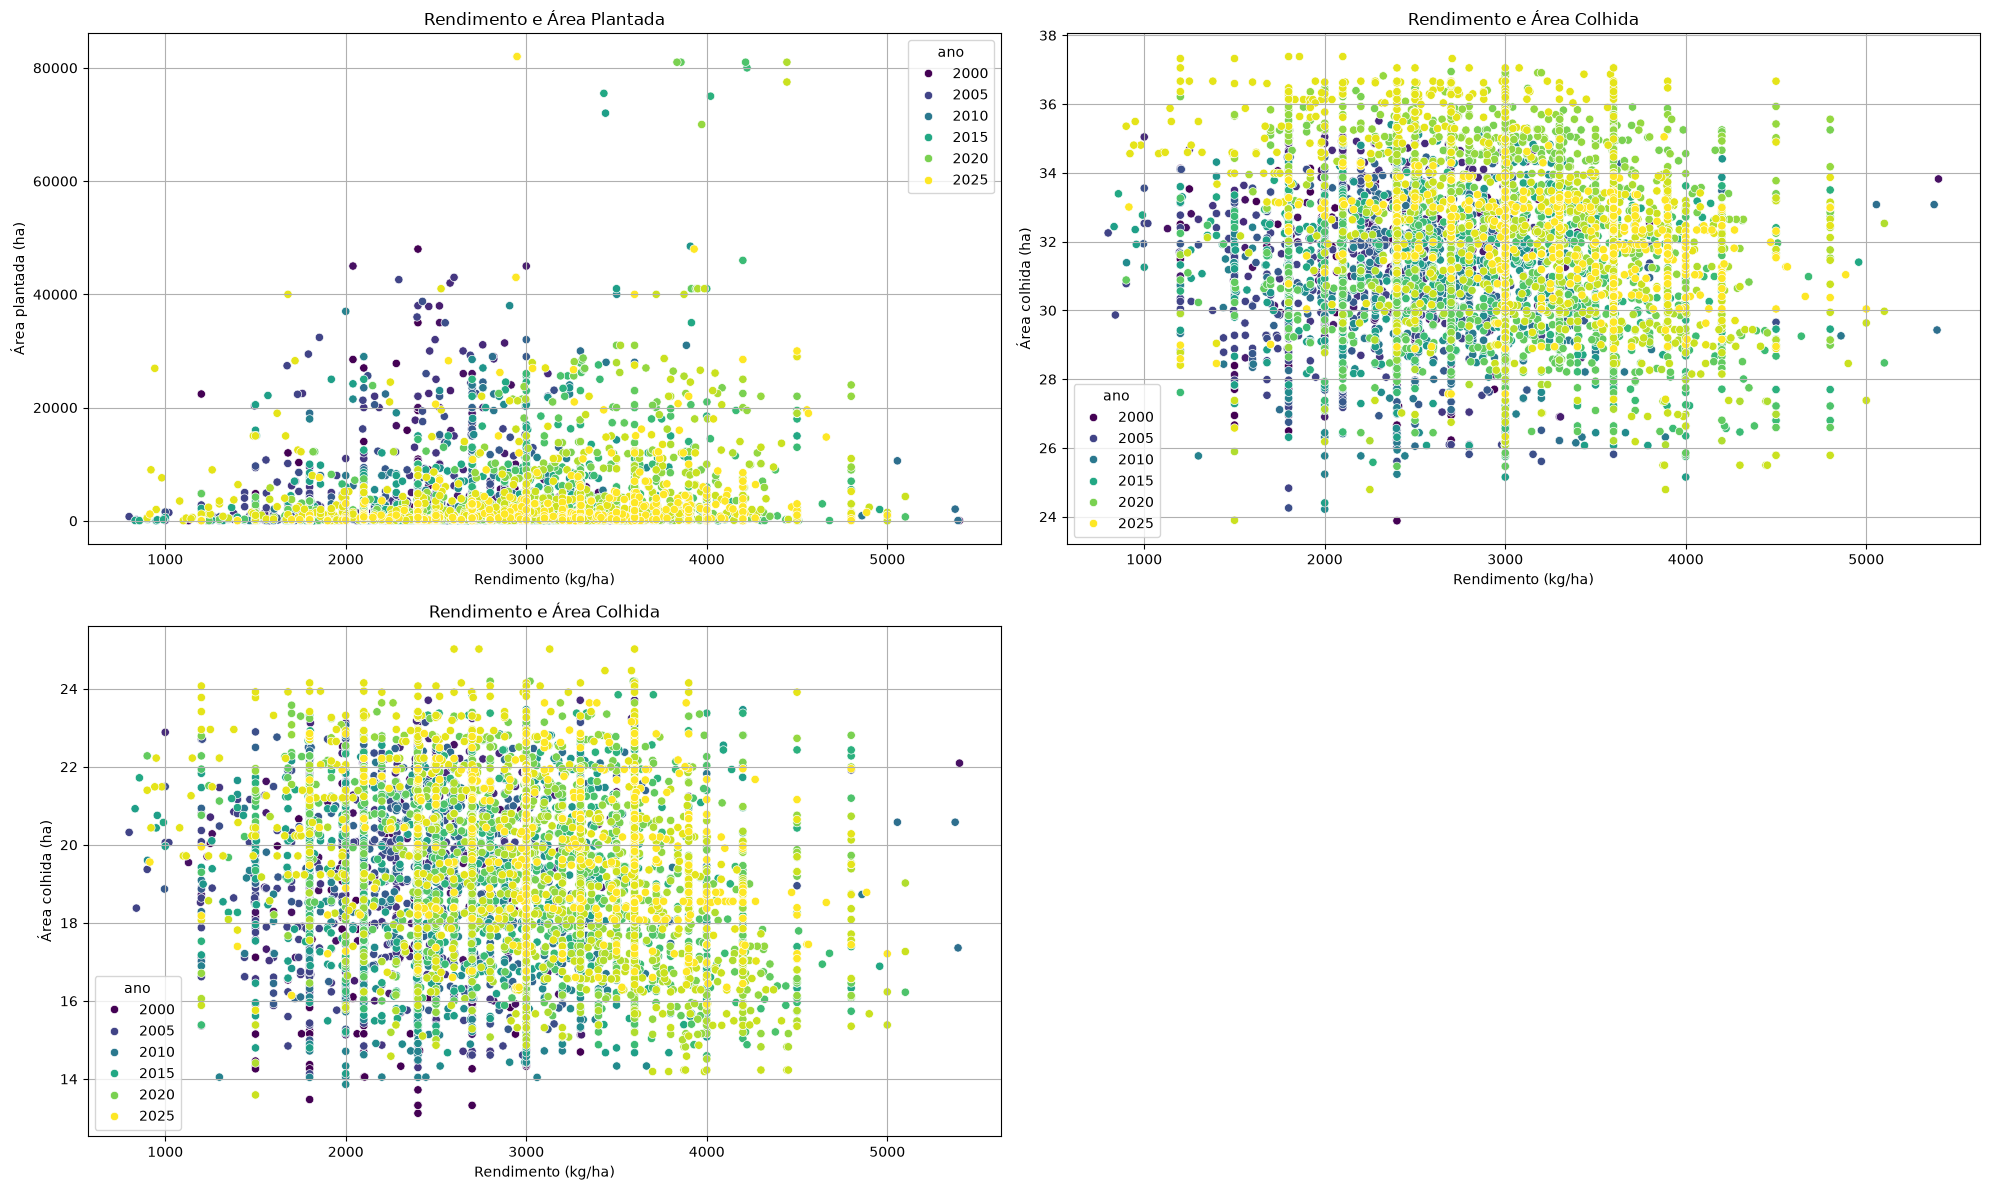

In [101]:
# relação area plantada e colhida


def plot_scatter_subplots(df, plots, ncols=2):
    nrows = math.ceil(len(plots) / ncols)

    fig, axes = plt.subplots(
        nrows, ncols, figsize=(10 * ncols, 6 * nrows), squeeze=False
    )
    axes = axes.ravel()

    for ax, (x, y, title, xlabel, ylabel) in zip(axes, plots):
        sns.scatterplot(
            data=df,
            x=x,
            y=y,
            marker="o",
            hue="ano",
            palette="viridis",
            ax=ax,
        )

        ax.set_title(title)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        ax.grid()

    for ax in axes[len(plots) :]:
        fig.delaxes(ax)

    plt.tight_layout()
    plt.show()


plot_scatter_subplots(
    df,
    [
        (
            "rendimento_kg_ha",
            "area_plantada_ha",
            "Rendimento e Área Plantada",
            "Rendimento (kg/ha)",
            "Área plantada (ha)",
        ),
        (
            "rendimento_kg_ha",
            "implant_tmax_c",
            "Rendimento e Área Colhida",
            "Rendimento (kg/ha)",
            "Área colhida (ha)",
        ),
        (
            "rendimento_kg_ha",
            "implant_tmin_c",
            "Rendimento e Área Colhida",
            "Rendimento (kg/ha)",
            "Área colhida (ha)",
        ),
    ],
)

Não há uma discriminação clara associada à relação entre a area plantada e o rendimento. Surge a hipótese que há outros fatores que influenciam um melhor rendimento. 

In [102]:
def plot_correlation_by_year(df, columns, year_col="ano", year=None):
    if year is not None:
        data = df.loc[df[year_col] == year, columns]
    else:
        data = df[columns]

    plt.figure(figsize=(10, 10))

    sns.heatmap(
        data.corr(numeric_only=True),
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1,
        center=0,
        square=True,
        linewidths=0.5,
    )

    title = (
        f"Correlação entre features — {year}"
        if year is not None
        else "Correlação entre features"
    )
    plt.title(title)
    plt.tight_layout()
    plt.show()

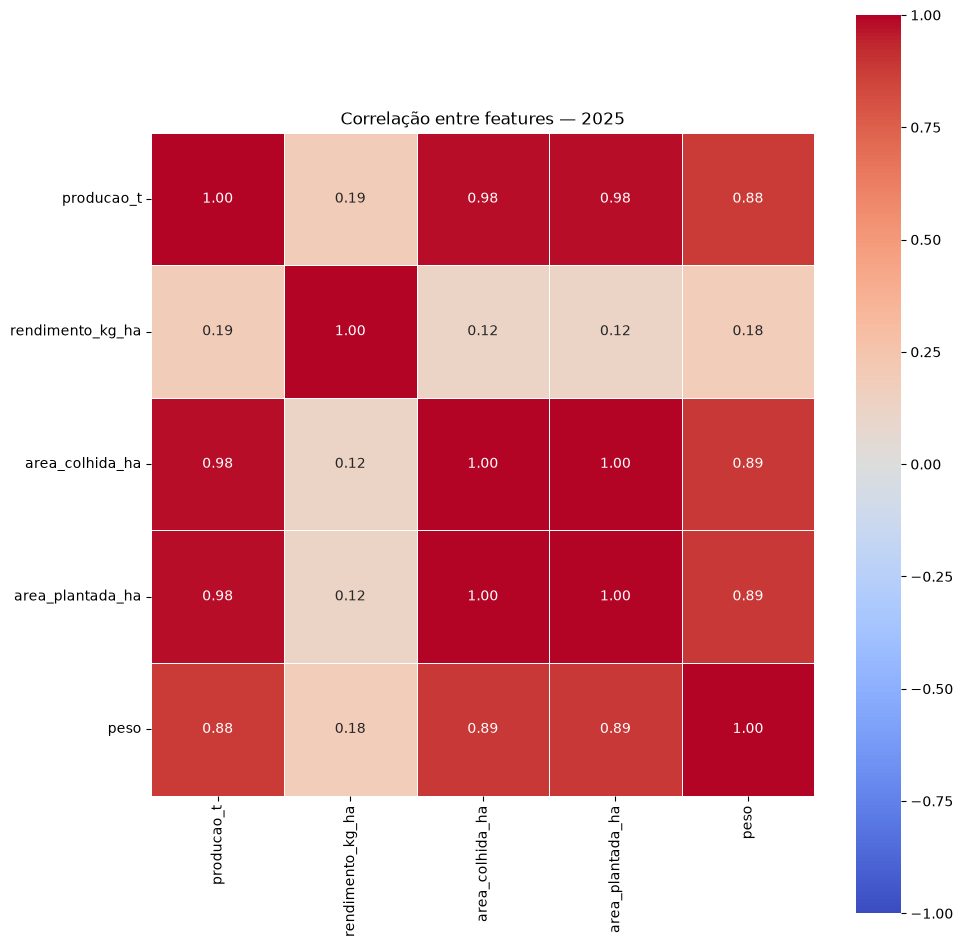

In [103]:
columns = [
    "producao_t",
    "rendimento_kg_ha",
    "area_colhida_ha",
    "area_plantada_ha",
    "peso",
]

plot_correlation_by_year(df, columns, year_col="ano", year=2025)

# Modelo

In [104]:
from sklearn.model_selection import train_test_split


# Definição do target e features
df.columns = original_columns
X = df.columns.difference(config.COLS_VAZAMENTO)
Y = "rendimento"

In [105]:
df_train, df_temp = train_test_split(df, test_size=0.30, random_state=42)
df_val, df_test = train_test_split(df_temp, test_size=0.50, random_state=42)

## Modelagem reproduzível

O `train_test_split` acima é mantido como referência da EDA, mas não será
usado para reportar desempenho. Como os dados formam um painel municipal,
os experimentos abaixo separam o teste antes do tuning e avaliam dois
cenários: novas observações dos mesmos municípios e municípios não vistos.
`ano`, identificadores e variáveis derivadas do alvo ficam fora de `X`.

In [67]:
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import ElasticNet
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import (
    GroupKFold,
    KFold,
    RandomizedSearchCV,
    StratifiedKFold,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


def preparar_modelagem(df):
    """Normaliza o CSV exportado e retorna dados prontos para os experimentos."""
    dados = unidades.para_modelagem(df.copy())
    alvo_col = "rendimento"
    if alvo_col not in dados:
        raise KeyError("O dataset precisa conter rendimento_kg_ha ou rendimento.")
    dados = dados.dropna(subset=[alvo_col]).copy()
    dados = dados[dados[alvo_col] > 0].copy()

    colunas_excluir = set(config.COLS_VAZAMENTO) | set(config.COLS_REDUNDANTES)
    colunas_excluir.update({"latitude", "longitude", "lat", "lon"})
    features = [
        c
        for c in dados.select_dtypes(include="number").columns
        if c not in colunas_excluir
        and c != alvo_col
        and dados[c].notna().mean() > 0.5
        and dados[c].nunique(dropna=True) > 1
    ]
    if not features:
        raise ValueError("Nenhuma feature numérica válida foi encontrada.")
    if "cod_ibge" not in dados:
        raise KeyError("cod_ibge é necessário para os cenários agrupados.")

    dados["y_log_modelo"] = np.log(dados[alvo_col])
    dados["bin_alvo"] = pd.qcut(
        dados["y_log_modelo"], q=10, labels=False, duplicates="drop"
    )
    return dados, features


dados_modelo, features_modelo = preparar_modelagem(
    pd.read_csv("../data/processed/dataset_soja.csv")
)
print(
    f"{len(dados_modelo):,} linhas, {dados_modelo['cod_ibge'].nunique():,} municípios, "
    f"{len(features_modelo)} features"
)

8,934 linhas, 521 municípios, 43 features


In [68]:
# O teste é um holdout de municípios inteiros. Ele fica intocado até a célula
# final, que apenas prepara as previsões para execução explícita pelo usuário.
rng = np.random.default_rng(42)
municipios = dados_modelo["cod_ibge"].drop_duplicates().to_numpy()
municipios_teste = set(
    rng.choice(municipios, size=max(1, round(0.20 * len(municipios))), replace=False)
)
eh_teste = dados_modelo["cod_ibge"].isin(municipios_teste)
desenvolvimento = dados_modelo.loc[~eh_teste].reset_index(drop=True)
teste_soja = dados_modelo.loc[eh_teste].reset_index(drop=True)

X_dev = desenvolvimento[features_modelo]
y_dev = desenvolvimento["y_log_modelo"]
grupos_dev = desenvolvimento["cod_ibge"]
bins_dev = desenvolvimento["bin_alvo"]
print(
    f"desenvolvimento={len(desenvolvimento):,} linhas / "
    f"{desenvolvimento['cod_ibge'].nunique():,} municípios; "
    f"teste reservado={len(teste_soja):,} linhas / "
    f"{teste_soja['cod_ibge'].nunique():,} municípios"
)

desenvolvimento=7,224 linhas / 417 municípios; teste reservado=1,710 linhas / 104 municípios


In [69]:
def pipeline_modelo(nome):
    """Tratamentos aprendidos no fold, seguidos de um regressor."""
    base = [("imputacao", SimpleImputer(strategy="median"))]
    if nome == "ElasticNet":
        base.append(("escala", StandardScaler()))
        base.append(("modelo", ElasticNet(max_iter=10000, random_state=42)))
    elif nome == "RandomForest":
        base.append(
            (
                "modelo",
                RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=1),
            )
        )
    elif nome == "HistGradientBoosting":
        base.append(
            (
                "modelo",
                HistGradientBoostingRegressor(max_iter=300, random_state=42),
            )
        )
    else:
        raise ValueError(f"Modelo desconhecido: {nome}")
    return Pipeline(base)


parametros = {
    "ElasticNet": {
        "modelo__alpha": np.logspace(-4, 1, 20),
        "modelo__l1_ratio": np.linspace(0.05, 0.95, 10),
    },
    "RandomForest": {
        "modelo__n_estimators": [200, 400, 700],
        "modelo__max_depth": [None, 8, 16, 24],
        "modelo__min_samples_leaf": [1, 2, 5, 10],
        "modelo__max_features": [0.5, 0.8, 1.0],
    },
    "HistGradientBoosting": {
        "modelo__learning_rate": [0.02, 0.05, 0.1],
        "modelo__max_iter": [150, 300, 500],
        "modelo__max_leaf_nodes": [7, 15, 31],
        "modelo__l2_regularization": [0.0, 1.0, 5.0],
        "modelo__min_samples_leaf": [10, 25, 50],
    },
}


def smape(y_real, y_previsto):
    denominador = np.abs(y_real) + np.abs(y_previsto)
    return float(
        np.mean(2 * np.abs(y_real - y_previsto) / np.maximum(denominador, 1e-9))
    )


def metricas_rendimento(y_log_real, y_log_previsto):
    real = np.exp(np.asarray(y_log_real))
    previsto = np.exp(np.asarray(y_log_previsto))
    return {
        "MAE_kg_ha": mean_absolute_error(real, previsto),
        "RMSE_kg_ha": mean_squared_error(real, previsto) ** 0.5,
        "R2_log": r2_score(y_log_real, y_log_previsto),
        "sMAPE": smape(real, previsto),
    }


def ajustar_modelos(dados, features, modo="mesmos_municipios", n_splits=5):
    """Tuning interno + validação externa, sem acessar o holdout."""
    X = dados[features]
    y = dados["y_log_modelo"]
    grupos = dados["cod_ibge"]
    bins = dados["bin_alvo"]
    if modo == "mesmos_municipios":
        cv_externo = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)
        # A busca recebe o alvo contínuo; estratificação por bins já é feita
        # no loop externo. No loop interno, KFold evita tratar cada valor
        # contínuo como uma classe distinta.
        cv_interno = KFold(n_splits=4, shuffle=True, random_state=43)
        split_externo = lambda: cv_externo.split(X, bins)
        split_interno = cv_interno
    elif modo == "municipios_novos":
        cv_externo = GroupKFold(n_splits=n_splits)
        cv_interno = GroupKFold(n_splits=4)
        split_externo = lambda: cv_externo.split(X, y, grupos)
        split_interno = cv_interno
    else:
        raise ValueError("modo deve ser 'mesmos_municipios' ou 'municipios_novos'")

    linhas = []
    melhores = {}
    for nome in parametros:
        folds = []
        for fold, (idx_treino, idx_validacao) in enumerate(split_externo(), 1):
            busca = RandomizedSearchCV(
                pipeline_modelo(nome),
                parametros[nome],
                n_iter=6,
                scoring="neg_root_mean_squared_error",
                cv=split_interno,
                random_state=42 + fold,
                n_jobs=1,
                refit=True,
            )
            grupos_internos = (
                grupos.iloc[idx_treino] if modo == "municipios_novos" else None
            )
            busca.fit(
                X.iloc[idx_treino],
                y.iloc[idx_treino],
                **({"groups": grupos_internos} if grupos_internos is not None else {}),
            )
            pred = busca.predict(X.iloc[idx_validacao])
            m = metricas_rendimento(y.iloc[idx_validacao], pred)
            m.update(modelo=nome, modo=modo, fold=fold)
            folds.append(m)
            melhores[(nome, modo, fold)] = busca.best_estimator_
        linhas.extend(folds)
    return pd.DataFrame(linhas), melhores

In [70]:
resultados_mesmos, modelos_mesmos = ajustar_modelos(
    desenvolvimento, features_modelo, modo="mesmos_municipios"
)
resultados_novos, modelos_novos = ajustar_modelos(
    desenvolvimento, features_modelo, modo="municipios_novos"
)
resultados_validacao = pd.concat(
    [resultados_mesmos, resultados_novos], ignore_index=True
)
resumo_validacao = (
    resultados_validacao.groupby(["modo", "modelo"])[
        ["MAE_kg_ha", "RMSE_kg_ha", "R2_log", "sMAPE"]
    ]
    .agg(["mean", "std"])
    .sort_values(("MAE_kg_ha", "mean"))
)
display(resumo_validacao.round(3))

c:\Users\Samsung\Documents\Projetos\agro_ml\agro_ml\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.086097e-02, tolerance: 2.710e-02
  model = cd_fast.enet_coordinate_descent(
c:\Users\Samsung\Documents\Projetos\agro_ml\agro_ml\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.440144e-02, tolerance: 2.719e-02
  model = cd_fast.enet_coordinate_descent(
c:\Users\Samsung\Documents\Projetos\agro_ml\agro_ml\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations

MAE_kg_ha        RMSE_kg_ha          \
                                            mean    std       mean     std   
modo              modelo                                                     
mesmos_municipios HistGradientBoosting   349.976  4.532    476.565   5.431   
                  RandomForest           357.004  5.108    486.928   7.699   
municipios_novos  HistGradientBoosting   357.783  8.421    483.681  15.453   
                  RandomForest           361.646  8.679    490.658  12.846   
mesmos_municipios ElasticNet             422.825  5.420    552.759  10.283   
municipios_novos  ElasticNet             423.893  6.825    553.478  10.648   

                                       R2_log         sMAPE         
                                         mean    std   mean    std  
modo              modelo                                            
mesmos_municipios HistGradientBoosting  0.463  0.004  0.130  0.002  
                  RandomForest          0.440  0.015  0.133  0.002  
municipios_novos  HistGradientBoosting  0.443  0.017  0.133  0.004  
                  RandomForest          0.429  0.017  0.134  0.004  
mesmos_municipios ElasticNet            0.285  0.019  0.156  0.002  
municipios_novos  ElasticNet            0.282  0.019  0.156  0.003

In [71]:
# Baseline: mediana do rendimento no treino de cada fold.
baseline = []
for modo, dados_cv in [
    ("mesmos_municipios", resultados_mesmos),
    ("municipios_novos", resultados_novos),
]:
    mediana_log = desenvolvimento["y_log_modelo"].median()
    baseline.append(
        {
            "modo": modo,
            "modelo": "Baseline_mediana",
            "MAE_kg_ha": metricas_rendimento(
                desenvolvimento["y_log_modelo"],
                np.full(len(desenvolvimento), mediana_log),
            )["MAE_kg_ha"],
        }
    )
display(pd.DataFrame(baseline))

,modo,modelo,MAE_kg_ha
0,mesmos_municipios,Baseline_mediana,531.237542
1,municipios_novos,Baseline_mediana,531.237542


In [72]:
# Diagnóstico agregado para orientar o segundo loop: erros por ano e por região.
# A região é a célula climática aproximada quando lat/lon está disponível.
def diagnostico_residuos(dados, modelo_por_fold, modo):
    linhas = []
    if "lat" in dados and "lon" in dados:
        regiao = (
            dados["lat"].round(1).astype(str) + "_" + dados["lon"].round(1).astype(str)
        )
    else:
        regiao = dados["cod_ibge"].astype(str)
    if modo == "mesmos_municipios":
        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
        splits = cv.split(dados[features_modelo], dados["bin_alvo"])
    else:
        cv = GroupKFold(n_splits=5)
        splits = cv.split(dados[features_modelo], groups=dados["cod_ibge"])
    for fold, (_, idx_val) in enumerate(splits, 1):
        modelo = modelo_por_fold[("HistGradientBoosting", modo, fold)]
        pred = modelo.predict(dados.iloc[idx_val][features_modelo])
        aux = dados.iloc[idx_val][["ano"]].copy()
        aux["regiao"] = regiao.iloc[idx_val].to_numpy()
        aux["erro_kg_ha"] = np.exp(dados.iloc[idx_val]["y_log_modelo"]) - np.exp(pred)
        linhas.append(aux)
    return pd.concat(linhas, ignore_index=True)


residuos_mesmos = diagnostico_residuos(
    desenvolvimento, modelos_mesmos, "mesmos_municipios"
)
residuos_novos = diagnostico_residuos(
    desenvolvimento, modelos_novos, "municipios_novos"
)
display(
    residuos_mesmos.groupby("ano")["erro_kg_ha"]
    .agg(["mean", "median", "count"])
    .round(1)
)
display(
    residuos_novos.groupby("regiao")["erro_kg_ha"]
    .agg(["mean", "median", "count"])
    .sort_values("mean")
    .head(15)
    .round(1)
)

,mean,median,count
ano,,,
2000,-5.2,-28.8,181
2001,-108.1,-121.1,187
2002,-40.1,-60.7,208
2003,-58.2,-68.7,244
2004,-79.5,-94.6,284
2005,-10.1,-2.1,277
2006,-41.7,-66.6,252
2007,3.4,11.2,255
2008,-24.0,-45.3,242


,mean,median,count
regiao,,,
-24.7_-47.9,-1369.5,-1369.5,2
-23.6_-46.2,-1208.7,-1208.7,2
-23.1_-47.1,-716.2,-903.5,5
-22.8_-48.2,-714.2,-774.2,10
-21.9_-49.3,-620.4,-620.4,2
-22.4_-49.8,-611.2,-683.7,21
-22.4_-47.7,-583.3,-583.3,1
-23.3_-47.1,-456.5,-456.5,2
-21.8_-50.2,-440.4,-74.2,7


## Segundo loop: melhorias guiadas pela validação

O loop compara o conjunto completo de features com uma versão reduzida,
removendo variáveis redundantes e features com ausência elevada. A escolha
final deve ser feita apenas pela média da validação e pela estabilidade
entre folds; o conjunto de teste continua sem ser consultado.

In [73]:
features_reduzidas = [
    c
    for c in features_modelo
    if c not in {"temp_media", "temp_min_media", "umidade_media", "vento_medio_ms"}
]
experimentos = {"completa": features_modelo, "reduzida": features_reduzidas}
melhorias = []
for nome_features, features in experimentos.items():
    r, _ = ajustar_modelos(
        desenvolvimento, features, modo="mesmos_municipios", n_splits=5
    )
    resumo = r.groupby("modelo")["MAE_kg_ha"].mean().sort_values()
    melhorias.extend(
        {"features": nome_features, "modelo": modelo, "MAE_medio_kg_ha": valor}
        for modelo, valor in resumo.items()
    )
resultado_melhorias = pd.DataFrame(melhorias).sort_values("MAE_medio_kg_ha")
display(resultado_melhorias.round(2))

c:\Users\Samsung\Documents\Projetos\agro_ml\agro_ml\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.086097e-02, tolerance: 2.710e-02
  model = cd_fast.enet_coordinate_descent(
c:\Users\Samsung\Documents\Projetos\agro_ml\agro_ml\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.440144e-02, tolerance: 2.719e-02
  model = cd_fast.enet_coordinate_descent(
c:\Users\Samsung\Documents\Projetos\agro_ml\agro_ml\.venv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations

,features,modelo,MAE_medio_kg_ha
0,completa,HistGradientBoosting,349.98
3,reduzida,HistGradientBoosting,349.98
1,completa,RandomForest,357.00
4,reduzida,RandomForest,357.00
2,completa,ElasticNet,422.83
5,reduzida,ElasticNet,422.83


## Treinamento e persistência do modelo final

O modelo final é treinado somente no conjunto de desenvolvimento. O holdout
municipal não é acessado nesta célula. O artefato inclui o pipeline, a lista
exata de features e metadados para permitir reprodução posterior.

In [74]:
melhor_linha = resultado_melhorias.iloc[0]
melhor_nome = melhor_linha["modelo"]
melhor_conjunto_features = melhor_linha["features"]
melhor_features = experimentos[melhor_conjunto_features]
modelo_final = pipeline_modelo(melhor_nome)
modelo_final.set_params(
    **modelos_mesmos[(melhor_nome, "mesmos_municipios", 1)].get_params()
)
modelo_final.fit(desenvolvimento[melhor_features], desenvolvimento["y_log_modelo"])

artefato_modelo = {
    "modelo": modelo_final,
    "features": melhor_features,
    "modelo_nome": melhor_nome,
    "conjunto_features": melhor_conjunto_features,
    "alvo": "log(rendimento_kg_ha)",
    "municipios_treino": desenvolvimento["cod_ibge"].unique(),
    "municipios_teste_reservados": teste_soja["cod_ibge"].unique(),
    "semente": 42,
    "observacao": "Treinado sem acessar o holdout municipal.",
}
config.DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)
caminho_modelo = config.DIR_RESULTADOS / "modelo_soja_final.joblib"
joblib.dump(artefato_modelo, caminho_modelo)
print(f"Modelo salvo em: {caminho_modelo}")

Modelo salvo em: C:\Users\Samsung\Documents\Projetos\agro_ml\agro_ml\resultados\modelo_soja_final.joblib


## Execução do teste (manual)

Esta célula fica desativada intencionalmente. Depois de revisar e aceitar o
modelo final, carregue o artefato e execute-a para gerar previsões do holdout.

In [106]:
artefato_carregado = joblib.load(config.DIR_RESULTADOS / "modelo_soja_final.joblib")
modelo_carregado = artefato_carregado["modelo"]
features_carregadas = artefato_carregado["features"]
previsoes_teste_kg_ha = np.exp(
    modelo_carregado.predict(teste_soja[features_carregadas])
)
saida_teste = teste_soja[["cod_ibge", "ano", "rendimento"]].copy()
saida_teste["previsao_kg_ha"] = previsoes_teste_kg_ha
saida_teste.to_csv(config.DIR_RESULTADOS / "previsoes_teste_soja.csv", index=False)
saida_teste.head()

,cod_ibge,ano,rendimento,previsao_kg_ha
0,3502002,2000,1800.0,2436.178033
1,3505906,2000,1980.0,2174.547165
2,3507456,2000,1200.0,2433.360459
3,3507704,2000,2400.0,2272.754769
4,3508207,2000,2100.0,2298.008440
